# 4 · Diffusion + proliferation — corrected

Corrected version of [`../04-diffusion-proliferation.ipynb`](../04-diffusion-proliferation.ipynb). The original is kept unchanged.

**Model** — Fisher–Kolmogorov equation:

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n + \alpha_0\, n\left(1 - \frac{n}{N_{\max}}\right)$$

**What changed from the original**

- **Growth term was multiplied by D.** As in notebook 3, the growth term sat inside the `(D / delta_x**2) * (...)` bracket, so the effective growth rate was $\alpha_0 D = 0.05$ instead of $\alpha_0 = 1$ (20× too slow). The original needed about 1000 steps to approach $N_{\max}$; the stated equation gets there in about 50.
- **Initial cutoff** (see the comment in the initial-condition cell).
- NumPy array operations instead of nested loops; the last snapshot is step 1000 (the original stopped plotting at 999).

> **Caveat — grid resolution.** The tumour edge is about $\sqrt{D/\alpha_0} \approx 0.2$ grid cells wide, so the spreading speed is still partly a grid effect (roughly 30 % faster than the continuum value $2\sqrt{D\alpha_0}$).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Parameters (same as the original)
l = 200
A = 0.05
σ1, σ2, σ3 = 15, 25, 12
delta_t = 0.1
delta_x = 1
D = 0.05
Alpha_zero = 1
N_Max = 1
cutoff = 1e-3     # new, see below
num_steps = 1000
save_steps = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

# The explicit scheme is only stable if D*dt/dx^2 <= 0.25 (2D, 5-point stencil)
assert D * delta_t / delta_x**2 <= 0.25, "unstable: reduce delta_t"

In [3]:
def laplacian(n):
    """5-point Laplacian. np.roll wraps around the edges, giving the same
    periodic boundaries as the original notebook."""
    return (np.roll(n, 1, axis=0) + np.roll(n, -1, axis=0)
            + np.roll(n, 1, axis=1) + np.roll(n, -1, axis=1) - 4 * n) / delta_x**2

In [4]:
# Same three Gaussian regions as the original notebook
i, j = np.meshgrid(np.arange(l), np.arange(l), indexing="ij")

def gaussian(ci, cj, sigma):
    return A * np.exp(-((i - ci)**2 + (j - cj)**2) / (2 * sigma**2))

n = gaussian(l/2, l/2 - 10, σ1) + gaussian(l/2, 3*l/4 - 30, σ2) + gaussian(2*l/5, 3*l/5 - 10, σ3)

# A Gaussian is never exactly zero. With logistic growth, even its 1e-30 tails
# grow exponentially and the whole grid fills up "spontaneously" within a few
# hundred steps. Treat densities below the cutoff as "no tumour cells".
n[n < cutoff] = 0.0

In [5]:
frames = {}
for step in range(1, num_steps + 1):
    n = n + delta_t * (D * laplacian(n) + Alpha_zero * n * (1 - n / N_Max))
    if step in save_steps:
        frames[step] = n.copy()

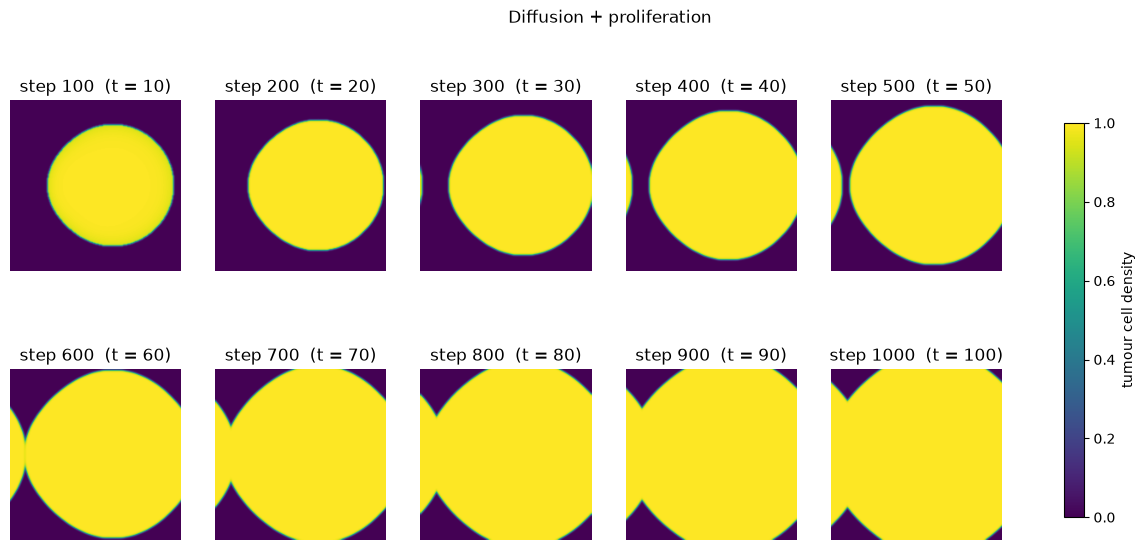

In [6]:
fig, axes = plt.subplots(int(np.ceil(len(frames) / 5)), 5, figsize=(3.2 * 5, 3.2 * int(np.ceil(len(frames) / 5))), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (step, frame) in zip(axes.flat, frames.items()):
    im = ax.imshow(frame, origin="lower", cmap="viridis", vmin=0, vmax=N_Max)
    ax.set_title(f"step {step}  (t = {step * delta_t:g})")
fig.colorbar(im, ax=axes, shrink=0.8, label="tumour cell density")
fig.suptitle("Diffusion + proliferation")
plt.show()

**Reading the result.** The tumour saturates at $N_{\max}$ and then grows as a front that moves outward at a steady speed, the classic Fisher–Kolmogorov travelling wave. With periodic boundaries, the front eventually wraps around the edges and closes up.